# Are CITES trade discrepancies systematic?
### Exporter vs. importer reported wildlife trade, and the role of governance quality

## 1. Introduction

Under CITES, every shipment of a listed species needs permits, and both the exporting and the importing country are supposed to report it in their annual reports. If both sides recorded the same shipments accurately, the two reported quantities would match. In practice they often do not. The CITES Trade Database lets us line up the *exporter-reported* and *importer-reported* quantity for the same year, species, trade term and country pair.

Some gaps are mundane: permits are issued in one year and the goods cross the border in the next, units or terms are recorded differently, taxonomy is inconsistent, or a record is rounded. Mundane error should be roughly symmetric and should not follow a pattern. Gaps are **systematic** if they have a consistent direction, recur within the same country pair and species, and are larger where institutions are weaker, which would point to under-reporting, weak enforcement or concealment rather than noise.

A caveat on scope: the CITES database records *reported legal and permitted trade*. Discrepancies are a signal that some trade may be unrecorded or misreported, but they are **not** a direct measure of illegal trafficking.

## 2. Research questions and hypotheses

**RQ1 (systematic?)** Are gaps between exporter- and importer-reported quantities (a) non-zero more often than chance reporting error would suggest, (b) consistently signed, and (c) persistent within a country pair across species, terms and years?

- *H1a:* the share of exactly matching records is low, and gaps are non-trivial in size.
- *H1b:* the direction of the gap is not 50/50: one side reports systematically more.
- *H1c:* signs of gaps agree within a country pair (across species, terms and years) more than independent coin flips would produce.

**RQ2 (governance)** Are gaps larger when trading countries have weaker governance (lower Corruption Perceptions Index, CPI)?

- *H2a:* relative gap size decreases with the CPI of the weaker-governed partner (`cpi_min`).
- *H2b:* the direction of the gap depends on *which* side has weak governance (e.g. exporter-reported quantities are higher than importer-reported ones when the importer has weak customs recording, and vice versa).

Because CPI is a country-level variable, we treat the country pair as the clustering unit throughout.

## 3. Data and approach

**Data needed**

1. **CITES Trade Database** [1, 2], comparative tabulation export from <https://trade.cites.org>. Expected columns: `Year, App., Taxon, Class, Order, Family, Genus, Importer, Exporter, Origin, Importer reported quantity, Exporter reported quantity, Term, Unit, Purpose, Source`. Country codes are ISO 3166-1 alpha-2.
2. **Transparency International CPI** [3], from <https://www.transparency.org/en/cpi>. It scores countries on how corrupt their public sectors are perceived to be, which is a perception measure and not a count of actual corruption cases. Each score is a composite of several outside sources, such as expert assessments and business surveys. The notebook averages whichever CPI years fall inside the analysis window (here, 2025).

**Method in brief**

- Collapse purpose, source and origin so that both sides are compared on the same dimensions: *year × species × term × unit × importer × exporter*. Purpose and source codes are often recorded differently by the two sides and would create spurious gaps.
- Keep only animal classes, and compare only within the same term and unit.
- Separate **non-reporting** (one side is blank) from **mismatch** (both sides report but disagree). The gap analysis uses records where both sides report.
- Gap measures for a record with exporter quantity *E* and importer quantity *I*:
  - signed gap = *E − I*
  - **relative gap** = |*E − I*| / max(*E*, *I*), in [0, 1], used for size
  - **symmetric gap** = (*E − I*) / (*E + I*), in [−1, 1], used for direction
- Aggregate to **series** = importer × exporter × species × term × unit, averaging over years, and merge on the mean CPI of each partner over the study window.

In [38]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---------------- configuration ----------------
USE_SYNTHETIC = False                   # True = synthetic test data (pipeline check only); False = the real files below
CITES_PATH = "reports.csv"              # CITES comparative tabulation, saved next to this notebook
CPI_PATH = "CPI2025_Results.xlsx"       # TI CPI 2025 results file
YEAR_MIN, YEAR_MAX = 2025, 2026         # analysis window (CITES trade years)
MIN_QTY = 1                     # drop records where max(E, I) is below this
MIN_PERSIST = 3                 # min records with a non-zero gap per country pair for the persistence test
MIN_GROUPS = 10                 # min number of such pairs needed to run that test
MIN_LEVEL = 15                  # control categories with fewer series than this are pooled into 'other'
SEED = 42
rng = np.random.default_rng(SEED)

#test data
ANIMAL_CLASSES = ["Mammalia", "Aves", "Reptilia", "Amphibia", "Actinopteri", "Actinopterygii", "Elasmobranchii",
                  "Holocephali", "Sarcopterygii", "Coelacanthi", "Dipneusti", "Cephalaspidomorphi", "Myxini",
                  "Insecta", "Arachnida", "Bivalvia", "Gastropoda", "Cephalopoda", "Anthozoa", "Hydrozoa",
                  "Holothuroidea", "Hirudinoidea", "Merostomata", "Malacostraca"]
R = {}  # collects key results for the summary cell

### Download settings

**File 1: CITES comparative tabulation** (<https://trade.cites.org>, search page, per the CITES Trade Database Guide [2])

| Setting | Value |
|---|---|
| Years | 2025 to 2026 (matches `YEAR_MIN`/`YEAR_MAX`). Save the file as `reports.csv` next to the notebook |
| Output | `.csv` file |
| Report type | **Comparative tabulation** (not gross/net) |
| Separator | Comma (if you choose semicolon, add `sep=";"` to `pd.read_csv`) |

Downloads are capped at one million rows. If the cap is hit, split the query (for example one file per year or per taxonomic class) and concatenate the files. This is safe because year is part of how rows are grouped, so splits do not create duplicate rows.

**Data timing.** CITES Parties submit their annual reports after the end of the trade year, so the most recent years are incomplete. Check the *Raw rows per year* printout in section 3.2: a year with far fewer rows than the other is mostly missing reports, and gaps in it would reflect late reporting, not misreporting. If 2026 is nearly empty, set `YEAR_MAX = 2025`.

**File 2: TI Corruption Perceptions Index.** `CPI2025_Results.xlsx` from the CPI page [3], saved next to the notebook. Each country gets a score from 0 (highly corrupt) to 100 (very clean). The scores in this file run from 9 to 89 across 182 countries.

### 3.1 Load data

In [39]:
def make_synthetic(n_series=5000, n_countries=60):
    """Synthetic CITES-like data in which gaps grow as governance weakens. For testing the pipeline only."""
    codes = [f"C{i:02d}" for i in range(n_countries)]
    cpi = pd.Series(rng.integers(12, 90, n_countries), index=codes)
    taxa = [f"Taxon {i:02d}" for i in range(40)]
    tclass = dict(zip(taxa, rng.choice(["Mammalia", "Aves", "Reptilia", "Actinopterygii"], 40)))
    rows = []
    for _ in range(n_series):
        imp, exp_ = rng.choice(codes, 2, replace=False)
        tx = rng.choice(taxa)
        term = rng.choice(["live", "bodies", "skins"], p=[.5, .3, .2])
        cmin = min(cpi[imp], cpi[exp_])
        sd = 0.03 + 0.8 * (100 - cmin) / 100
        p_match = 0.1 + 0.5 * cmin / 100
        for y in rng.choice(np.arange(YEAR_MIN, YEAR_MAX + 1), rng.integers(1, min(7, YEAR_MAX - YEAR_MIN + 2)), replace=False):
            q = rng.lognormal(3, 1.4)
            e = float(max(1, round(q)))
            i = float(max(1, round(q * np.exp(rng.normal(0.05, sd)))))
            if rng.random() < p_match:
                i = e
            if rng.random() < 0.12:
                i = np.nan
            elif rng.random() < 0.08:
                e = np.nan
            rows.append({"Year": y, "Taxon": tx, "Class": tclass[tx], "Importer": imp, "Exporter": exp_,
                         "Term": term, "Unit": None,
                         "Importer reported quantity": i, "Exporter reported quantity": e})
    gov = pd.DataFrame({"code": codes, "cpi": cpi.values})
    return pd.DataFrame(rows), gov


# ISO 3166-1 alpha-3 -> alpha-2 (CITES reports use alpha-2; TI uses alpha-3). Kosovo: TI 'KSV' (or 'XKX'), CITES 'KV'.
ISO3_TO_ISO2 = dict(p.split(":") for p in (
    "AFG:AF ALB:AL DZA:DZ ASM:AS AND:AD AGO:AO AIA:AI ATA:AQ ATG:AG ARG:AR ARM:AM ABW:AW AUS:AU AUT:AT AZE:AZ "
    "BHS:BS BHR:BH BGD:BD BRB:BB BLR:BY BEL:BE BLZ:BZ BEN:BJ BMU:BM BTN:BT BOL:BO BES:BQ BIH:BA BWA:BW BVT:BV "
    "BRA:BR IOT:IO BRN:BN BGR:BG BFA:BF BDI:BI CPV:CV KHM:KH CMR:CM CAN:CA CYM:KY CAF:CF TCD:TD CHL:CL CHN:CN "
    "CXR:CX CCK:CC COL:CO COM:KM COG:CG COD:CD COK:CK CRI:CR CIV:CI HRV:HR CUB:CU CUW:CW CYP:CY CZE:CZ DNK:DK "
    "DJI:DJ DMA:DM DOM:DO ECU:EC EGY:EG SLV:SV GNQ:GQ ERI:ER EST:EE SWZ:SZ ETH:ET FLK:FK FRO:FO FJI:FJ FIN:FI "
    "FRA:FR GUF:GF PYF:PF ATF:TF GAB:GA GMB:GM GEO:GE DEU:DE GHA:GH GIB:GI GRC:GR GRL:GL GRD:GD GLP:GP GUM:GU "
    "GTM:GT GGY:GG GIN:GN GNB:GW GUY:GY HTI:HT HMD:HM VAT:VA HND:HN HKG:HK HUN:HU ISL:IS IND:IN IDN:ID IRN:IR "
    "IRQ:IQ IRL:IE IMN:IM ISR:IL ITA:IT JAM:JM JPN:JP JEY:JE JOR:JO KAZ:KZ KEN:KE KIR:KI PRK:KP KOR:KR KWT:KW "
    "KGZ:KG LAO:LA LVA:LV LBN:LB LSO:LS LBR:LR LBY:LY LIE:LI LTU:LT LUX:LU MAC:MO MDG:MG MWI:MW MYS:MY MDV:MV "
    "MLI:ML MLT:MT MHL:MH MTQ:MQ MRT:MR MUS:MU MYT:YT MEX:MX FSM:FM MDA:MD MCO:MC MNG:MN MNE:ME MSR:MS MAR:MA "
    "MOZ:MZ MMR:MM NAM:NA NRU:NR NPL:NP NLD:NL NCL:NC NZL:NZ NIC:NI NER:NE NGA:NG NIU:NU NFK:NF MKD:MK MNP:MP "
    "NOR:NO OMN:OM PAK:PK PLW:PW PSE:PS PAN:PA PNG:PG PRY:PY PER:PE PHL:PH PCN:PN POL:PL PRT:PT PRI:PR QAT:QA "
    "REU:RE ROU:RO RUS:RU RWA:RW BLM:BL SHN:SH KNA:KN LCA:LC MAF:MF SPM:PM VCT:VC WSM:WS SMR:SM STP:ST SAU:SA "
    "SEN:SN SRB:RS SYC:SC SLE:SL SGP:SG SXM:SX SVK:SK SVN:SI SLB:SB SOM:SO ZAF:ZA SGS:GS SSD:SS ESP:ES LKA:LK "
    "SDN:SD SUR:SR SJM:SJ SWE:SE CHE:CH SYR:SY TWN:TW TJK:TJ TZA:TZ THA:TH TLS:TL TGO:TG TKL:TK TON:TO TTO:TT "
    "TUN:TN TUR:TR TKM:TM TCA:TC TUV:TV UGA:UG UKR:UA ARE:AE GBR:GB USA:US UMI:UM URY:UY UZB:UZ VUT:VU VEN:VE "
    "VNM:VN VGB:VG VIR:VI WLF:WF ESH:EH YEM:YE ZMB:ZM ZWE:ZW ALA:AX XKX:KV KSV:KV").split())


def _strip_defined_names(path):
    """Copy of an .xlsx with the workbook's 'defined names' removed (openpyxl crashes on stale ones)."""
    import io, zipfile
    buf = io.BytesIO()
    with zipfile.ZipFile(path) as zin, zipfile.ZipFile(buf, "w", zipfile.ZIP_DEFLATED) as zout:
        for item in zin.infolist():
            data = zin.read(item.filename)
            if item.filename == "xl/workbook.xml":
                data = re.sub(rb"<(?:\w+:)?definedNames>.*?</(?:\w+:)?definedNames>", b"", data, flags=re.S)
            zout.writestr(item, data)
    buf.seek(0)
    return buf


def _read_xlsx_raw(path):
    """Minimal .xlsx reader (zip + XML, namespace-agnostic) for files that openpyxl cannot parse."""
    import zipfile
    import xml.etree.ElementTree as ET
    def local(tag):
        return tag.rsplit("}", 1)[-1]
    def col_index(ref):
        n = 0
        for ch in re.match(r"[A-Za-z]+", ref).group(0).upper():
            n = n * 26 + (ord(ch) - 64)
        return n - 1
    with zipfile.ZipFile(path) as z:
        names = z.namelist()
        shared = []
        if "xl/sharedStrings.xml" in names:
            for si in ET.fromstring(z.read("xl/sharedStrings.xml")):
                if local(si.tag) == "si":
                    shared.append("".join(t.text or "" for t in si.iter() if local(t.tag) == "t"))
        parts = {}                                   # sheet name -> xml part
        if "xl/workbook.xml" in names:
            rels = {}
            if "xl/_rels/workbook.xml.rels" in names:
                for r in ET.fromstring(z.read("xl/_rels/workbook.xml.rels")):
                    tgt = r.attrib.get("Target", "")
                    rels[r.attrib.get("Id")] = tgt.lstrip("/") if tgt.startswith("/") else "xl/" + tgt
            for el in ET.fromstring(z.read("xl/workbook.xml")).iter():
                if local(el.tag) == "sheet":
                    rid = next((v for k, v in el.attrib.items() if local(k) == "id"), None)
                    if rid in rels:
                        parts[el.attrib.get("name", rid)] = rels[rid]
        if not parts:                                # no usable workbook map: take worksheet parts in file order
            for n in sorted(x for x in names if re.match(r"xl/worksheets/[^/]+\.xml$", x)):
                parts[n.split("/")[-1][:-4]] = n
        if not parts:
            raise ValueError("No worksheets found in the file. Zip contents: " + ", ".join(names[:25]))
        out = {}
        for sname, part in parts.items():
            if part not in names:
                continue
            cells = {}
            for c in ET.fromstring(z.read(part)).iter():
                if local(c.tag) != "c" or not c.attrib.get("r"):
                    continue
                ref, t = c.attrib["r"], c.attrib.get("t", "n")
                v = next((x for x in c if local(x.tag) == "v"), None)
                if t == "inlineStr":
                    val = "".join(x.text or "" for x in c.iter() if local(x.tag) == "t")
                elif v is None or v.text is None:
                    continue
                elif t == "s":
                    val = shared[int(v.text)]
                elif t in ("str", "e"):
                    val = v.text
                elif t == "b":
                    val = bool(int(v.text))
                else:
                    try:
                        val = float(v.text)
                    except ValueError:
                        val = v.text
                cells[(int(re.search(r"\d+", ref).group(0)) - 1, col_index(ref))] = val
            if cells:
                nr, nc = max(r for r, _ in cells) + 1, max(c for _, c in cells) + 1
                grid = [[None] * nc for _ in range(nr)]
                for (r, c), val in cells.items():
                    grid[r][c] = val
                out[sname] = pd.DataFrame(grid)
    return out


def _read_excel_all_sheets(path):
    """Try pandas/openpyxl, then openpyxl without defined names, then the raw zip/XML reader."""
    attempts = [lambda: pd.read_excel(path, header=None, sheet_name=None),
                lambda: pd.read_excel(_strip_defined_names(path), header=None, sheet_name=None),
                lambda: _read_xlsx_raw(path)]
    for k, attempt in enumerate(attempts):
        try:
            sheets = attempt()
            if sheets:
                return sheets
        except Exception:
            if k == len(attempts) - 1:
                raise
    raise ValueError("No readable sheets in the Excel file.")


def read_cpi_table(path):
    """Read a TI CPI file (.xlsx/.csv, wide or long) into a long table: iso3, year, cpi."""
    def find_header(df):
        for i in range(min(30, len(df))):
            if any(str(v).strip().lower().startswith("iso") for v in df.iloc[i]):
                return i
        return None
    if str(path).lower().endswith((".xlsx", ".xls")):
        sheets = _read_excel_all_sheets(path)   # all sheets; first one with an ISO column wins
    else:
        sheets = {"csv": pd.read_csv(path, header=None)}
    for name, raw_cpi in sheets.items():
        hdr = find_header(raw_cpi)
        if hdr is not None:
            break
    else:
        raise ValueError("No sheet with an ISO3 column found in the CPI file; check the file or set the header manually.")
    cpi = raw_cpi.iloc[hdr + 1:].copy()
    cpi.columns = [str(c).strip() for c in raw_cpi.iloc[hdr]]
    iso_col = next(c for c in cpi.columns if c.lower().startswith("iso"))
    if {"year", "cpi"} <= {c.lower() for c in cpi.columns}:           # already long
        cpi = cpi.rename(columns={iso_col: "iso3", **{c: c.lower() for c in cpi.columns if c.lower() in ("year", "cpi")}})
        out = cpi[["iso3", "year", "cpi"]]
    else:                                                             # wide: one column per year
        has_year = [c for c in cpi.columns if re.search(r"(19|20)\d\d", c)]
        score_cols = [c for c in has_year if "score" in c.lower()]
        if not score_cols:                                            # fall back: year columns that are not rank/error/CI/sources
            bad = ("rank", "error", "lower", "upper", "ci", "source", "std")
            score_cols = [c for c in has_year if not any(b in c.lower() for b in bad)]
        out = cpi.melt(id_vars=[iso_col], value_vars=score_cols, var_name="v", value_name="cpi")
        out["year"] = out["v"].str.extract(r"((?:19|20)\d\d)")[0]
        out = out.rename(columns={iso_col: "iso3"})[["iso3", "year", "cpi"]]
    out["year"] = pd.to_numeric(out["year"], errors="coerce")
    out["cpi"] = pd.to_numeric(out["cpi"], errors="coerce")
    return out.dropna(subset=["iso3", "year", "cpi"])


def load_cpi_real(path, year_min, year_max):
    """Return one row per CITES country code (ISO2) with the mean CPI over the window."""
    cpi = read_cpi_table(path)
    cpi = cpi[cpi["year"].between(year_min, year_max)]
    gov = cpi.groupby("iso3", as_index=False)["cpi"].mean()
    gov["code"] = gov["iso3"].map(ISO3_TO_ISO2)
    unmatched = gov.loc[gov["code"].isna(), "iso3"].tolist()
    print(f"CPI: {gov['code'].notna().sum()} countries matched to ISO2 codes, mean score {gov['cpi'].mean():.1f} (expect 0-100 scale)"
          + (f"; unmatched ISO3: {unmatched}" if unmatched else ""))
    return gov.dropna(subset=["code"])[["code", "cpi"]]


if USE_SYNTHETIC:
    raw, gov = make_synthetic()
    print("USING SYNTHETIC DATA - results are not real.")
else:
    raw = pd.read_csv(CITES_PATH, low_memory=False)
    if raw.shape[1] == 1:                      # semicolon-separated export
        raw = pd.read_csv(CITES_PATH, sep=";", low_memory=False)
    gov = load_cpi_real(CPI_PATH, YEAR_MIN, YEAR_MAX)

raw.columns = [c.strip().lower().replace(".", "").replace(" ", "_") for c in raw.columns]
raw = raw.rename(columns={"class": "class_",
                          "importer_reported_quantity": "imp",
                          "exporter_reported_quantity": "exp"})
need = {"year", "taxon", "class_", "importer", "exporter", "term", "unit", "imp", "exp"}
assert need <= set(raw.columns), f"Missing columns: {sorted(need - set(raw.columns))}. Check the export is a Comparative Tabulation."
print(raw.shape, "| countries with governance data:", gov["code"].nunique())
raw.head()

CPI: 182 countries matched to ISO2 codes, mean score 42.5 (expect 0-100 scale)
(30781, 16) | countries with governance data: 182


,year,app,taxon,class_,order,family,genus,importer,exporter,origin,imp,exp,term,unit,purpose,source
0,2025,I,Aquila heliaca,Aves,Falconiformes,Accipitridae,Aquila,DE,AZ,NaN,2.000,2.000,feathers,Number of specimens,S,C
1,2025,I,Haliaeetus albicilla,Aves,Falconiformes,Accipitridae,Haliaeetus,AT,GB,XX,2.000,NaN,bodies,Number of specimens,T,O
2,2025,I,Haliaeetus albicilla,Aves,Falconiformes,Accipitridae,Haliaeetus,DE,AZ,NaN,2.000,2.000,feathers,Number of specimens,S,C
3,2025,I,Haliaeetus albicilla,Aves,Falconiformes,Accipitridae,Haliaeetus,GB,IE,XX,NaN,2.000,specimens,Number of specimens,S,O
4,2025,I,Haliaeetus albicilla,Aves,Falconiformes,Accipitridae,Haliaeetus,IE,NO,NaN,30.000,NaN,live,Number of specimens,N,W


### 3.2 Clean and build comparable records

In [40]:
df = raw.copy()
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)]
print("Raw rows per year (check for incomplete reporting in the latest year):")
print(df.groupby("year").size().to_string())
if not USE_SYNTHETIC:
    df = df[df["class_"].isin(ANIMAL_CLASSES)]
for c in ("imp", "exp"):
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["unit"] = df["unit"].fillna("Number of specimens")
df["term"] = df["term"].fillna("unknown")

KEY = ["importer", "exporter", "taxon", "class_", "term", "unit"]

# collapse purpose / source / origin; min_count=1 keeps a blank as blank instead of 0
annual = (df.groupby(KEY + ["year"])[["imp", "exp"]].sum(min_count=1).reset_index())

annual["status"] = np.select(
    [annual["imp"].notna() & annual["exp"].notna(),
     annual["imp"].isna() & annual["exp"].notna(),
     annual["imp"].notna() & annual["exp"].isna()],
    ["both report", "only exporter reports", "only importer reports"], default="neither")

status_share = annual["status"].value_counts(normalize=True)
R["status_share"] = status_share
print("Reporting status of year x species x term x pair records:")
print(status_share.to_frame("share"))
R["cov_imp"] = annual.loc[annual["imp"].notna(), "importer"].nunique()
R["cov_exp"] = annual.loc[annual["exp"].notna(), "exporter"].nunique()
print(f"\nCountries with any importer-side report: {R['cov_imp']} | with any exporter-side report: {R['cov_exp']}")
print("Most active exporter-side reporters (records):", annual.loc[annual["exp"].notna(), "exporter"].value_counts().head(8).to_dict())
print("Most active importer-side reporters (records):", annual.loc[annual["imp"].notna(), "importer"].value_counts().head(8).to_dict())

both = annual[annual["status"] == "both report"].copy()
both = both[np.maximum(both["imp"], both["exp"]) >= MIN_QTY]

both["signed_gap"] = both["exp"] - both["imp"]
both["abs_gap"] = both["signed_gap"].abs()
both["rel_gap"] = both["abs_gap"] / np.maximum(both["exp"], both["imp"])
both["sym_gap"] = both["signed_gap"] / (both["exp"] + both["imp"])
print(f"\nComparable records (both sides report, max qty >= {MIN_QTY}): {len(both):,}")
both.head()

Raw rows per year (check for incomplete reporting in the latest year):
year
2025    30779
2026        2
Reporting status of year x species x term x pair records:
                       share
status                      
only exporter reports  0.686
only importer reports  0.295
both report            0.019

Countries with any importer-side report: 38 | with any exporter-side report: 50
Most active exporter-side reporters (records): {'IT': 1620, 'FR': 1554, 'DE': 1155, 'BE': 678, 'CZ': 658, 'ES': 615, 'NL': 544, 'CY': 196}
Most active importer-side reporters (records): {'DE': 753, 'FR': 658, 'IT': 521, 'ES': 295, 'NL': 205, 'TR': 192, 'AT': 187, 'CZ': 177}

Comparable records (both sides report, max qty >= 1): 232


,importer,exporter,taxon,class_,term,unit,year,imp,exp,status,signed_gap,abs_gap,rel_gap,sym_gap
581,AT,AZ,Ursus arctos,Mammalia,live,Number of specimens,2025,1.000,1.000,both report,0.000,0.000,0.000,0.000
705,AT,TR,Capra hircus aegagrus,Mammalia,trophies,Number of specimens,2025,2.000,1.000,both report,-1.000,1.000,0.500,-0.333
914,BA,CZ,Aonyx cinereus,Mammalia,live,Number of specimens,2025,2.000,2.000,both report,0.000,0.000,0.000,0.000
915,BA,CZ,Arctictis binturong,Mammalia,live,Number of specimens,2025,2.000,2.000,both report,0.000,0.000,0.000,0.000
916,BA,CZ,Hylobates lar,Mammalia,live,Number of specimens,2025,2.000,2.000,both report,0.000,0.000,0.000,0.000


### 3.3 Gap per country pair and species
The table below is the main object requested: for each importer × exporter × species (× term × unit) series, the total and average gap across years.

In [41]:
series = (both.groupby(KEY)
          .agg(n_years=("year", "nunique"),
               imp_total=("imp", "sum"), exp_total=("exp", "sum"),
               mean_rel_gap=("rel_gap", "mean"),
               mean_sym_gap=("sym_gap", "mean"),
               share_mismatch=("abs_gap", lambda s: (s > 0).mean()))
          .reset_index())
series["net_gap"] = series["exp_total"] - series["imp_total"]            # E - I over all years
series["rel_gap_total"] = series["net_gap"].abs() / np.maximum(series["exp_total"], series["imp_total"])
series["log_vol"] = np.log1p(series["imp_total"] + series["exp_total"])
series["log_n"] = np.log(series["n_years"])
series["pair_id"] = pd.factorize(series["importer"] + "_" + series["exporter"])[0]

print(f"{len(series):,} series | {series['pair_id'].nunique():,} country pairs | {series['taxon'].nunique():,} taxa")
series.sort_values("net_gap", key=np.abs, ascending=False).head(10)

232 series | 55 country pairs | 119 taxa


,importer,exporter,taxon,class_,term,unit,n_years,imp_total,exp_total,mean_rel_gap,mean_sym_gap,share_mismatch,net_gap,rel_gap_total,log_vol,log_n,pair_id
42,DE,CO,Caiman crocodilus fuscus,Reptilia,skins,Number of specimens,1,"17,216.000","9,607.000",0.442,-0.284,1.000,"-7,609.000",0.442,10.197,0.000,8
55,ES,CV,Prionace glauca,Elasmobranchii,bodies,kg,1,"364,614.000","371,563.000",0.019,0.009,1.000,"6,949.000",0.019,13.509,0.000,17
84,IT,PE,Vicugna vicugna,Mammalia,fibres,kg,1,"7,623.000",793.310,0.896,-0.811,1.000,"-6,829.690",0.896,9.038,0.000,30
83,IT,PE,Pecari tajacu,Mammalia,skins,Number of specimens,1,"3,533.000","1,660.000",0.530,-0.361,1.000,"-1,873.000",0.530,8.555,0.000,30
68,FR,FR,Tridacna maxima,Bivalvia,live,Number of specimens,1,"1,624.000",226.000,0.861,-0.756,1.000,"-1,398.000",0.861,7.523,0.000,22
96,MO,FR,Alligator mississippiensis,Reptilia,leather products (small),Number of specimens,1,93.000,"1,142.500",0.919,0.849,1.000,"1,049.500",0.919,7.120,0.000,33
152,TR,CZ,Psephotus haematonotus,Aves,live,Number of specimens,1,"1,050.000",285.000,0.729,-0.573,1.000,-765.000,0.729,7.197,0.000,46
144,TR,CZ,Myiopsitta monachus,Aves,live,Number of specimens,1,670.000,121.000,0.819,-0.694,1.000,-549.000,0.819,6.675,0.000,46
127,TR,CZ,Agapornis fischeri,Aves,live,Number of specimens,1,"1,000.000",510.000,0.490,-0.325,1.000,-490.000,0.490,7.321,0.000,46
148,TR,CZ,Platycercus eximius,Aves,live,Number of specimens,1,"1,050.000",596.000,0.432,-0.276,1.000,-454.000,0.432,7.407,0.000,46


## 4. Analysis

### 4.1 Descriptives: how big are the gaps?

Share of records with exactly matching quantities: 40.1%
Relative gap: mean 0.307, median 0.170


,records,share_exact,mean_rel_gap,mean_sym_gap
class_,,,,
Reptilia,90,0.256,0.323,0.119
Aves,64,0.484,0.326,-0.222
Mammalia,49,0.510,0.247,0.085
Actinopteri,18,0.444,0.370,0.299
Elasmobranchii,4,0.250,0.300,0.196
Amphibia,2,1.000,0.000,0.000
Anthozoa,2,0.500,0.250,0.167
Bivalvia,1,0.000,0.861,-0.756
Cephalopoda,1,1.000,0.000,0.000


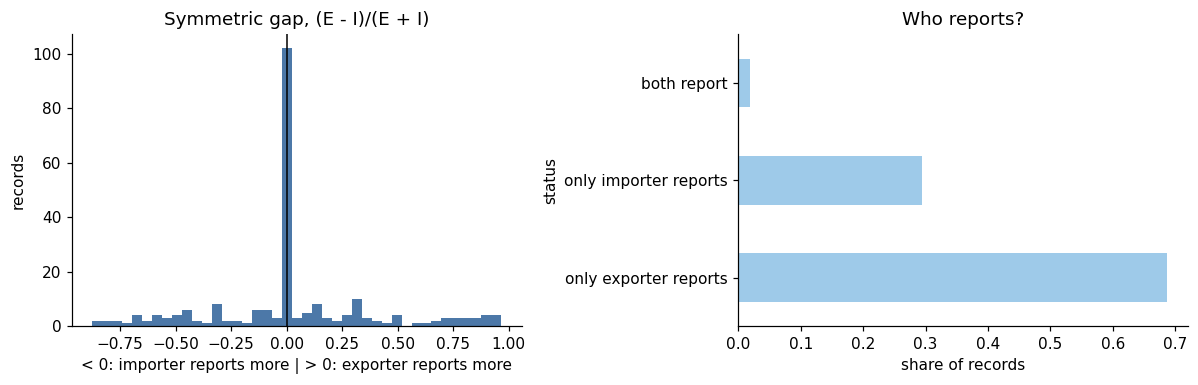

In [42]:
R["share_exact"] = (both["abs_gap"] == 0).mean()
R["median_rel_gap"] = both["rel_gap"].median()
R["mean_rel_gap"] = both["rel_gap"].mean()
print(f"Share of records with exactly matching quantities: {R['share_exact']:.1%}")
print(f"Relative gap: mean {R['mean_rel_gap']:.3f}, median {R['median_rel_gap']:.3f}")

by_class = (both.groupby("class_")
            .agg(records=("rel_gap", "size"),
                 share_exact=("abs_gap", lambda s: (s == 0).mean()),
                 mean_rel_gap=("rel_gap", "mean"),
                 mean_sym_gap=("sym_gap", "mean"))
            .sort_values("records", ascending=False))
display(by_class)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(both["sym_gap"], bins=41, color="#4c78a8")
ax[0].axvline(0, color="k", lw=1)
ax[0].set(title="Symmetric gap, (E - I)/(E + I)", xlabel="< 0: importer reports more | > 0: exporter reports more", ylabel="records")
status_share.plot.barh(ax=ax[1], color="#9ecae9")
ax[1].set(title="Who reports?", xlabel="share of records")
plt.tight_layout(); plt.show()

### 4.2 RQ1: are gaps systematic?
Three checks, each addressing one sub-hypothesis. Records within the same country pair are not independent, so tests on direction use **pair-level means** rather than raw records.

In [43]:
# (b) direction: is one side reporting more than the other?
pos = int((both["sym_gap"] > 0).sum()); neg = int((both["sym_gap"] < 0).sum())
R["pos"], R["neg"] = pos, neg
binom = st.binomtest(pos, pos + neg, 0.5)
print(f"Exporter reports more in {pos:,} records, importer in {neg:,} "
      f"({pos/(pos+neg):.1%} vs 50% expected); binomial p = {binom.pvalue:.3g}")

pair_mean = both.groupby(["importer", "exporter"])["sym_gap"].mean()
w = st.wilcoxon(pair_mean[pair_mean != 0])
t = st.ttest_1samp(pair_mean, 0)
R["pair_mean_sym"], R["wilcoxon_p"] = pair_mean.mean(), w.pvalue
print(f"Pair-level mean symmetric gap = {pair_mean.mean():.3f} (n pairs = {len(pair_mean):,}); "
      f"t-test p = {t.pvalue:.3g}, Wilcoxon p = {w.pvalue:.3g}")

# (c) persistence: within a country pair, do gaps lean the same way across species, terms and years more than coin flips would?
nz = both[both["sym_gap"] != 0].copy()
nz["sign"] = np.sign(nz["sym_gap"])
g = nz.groupby(["importer", "exporter"])["sign"].agg(n="size", m="mean")
g = g[g["n"] >= MIN_PERSIST]
obs, null_mean, p_persist = np.nan, np.nan, np.nan
if len(g) >= MIN_GROUPS:
    obs = (g["m"] ** 2).mean()
    n_arr = g["n"].to_numpy()
    sims = np.array([((2 * rng.binomial(n_arr, 0.5) / n_arr - 1) ** 2).mean() for _ in range(2000)])
    null_mean = sims.mean()
    p_persist = (np.sum(sims >= obs) + 1) / (len(sims) + 1)
    print(f"\nPersistence of gap sign within country pairs ({len(g):,} pairs with >= {MIN_PERSIST} non-zero gaps):")
    print(f"  mean squared share-of-same-sign: observed {obs:.3f} vs {null_mean:.3f} under random signs; permutation p = {p_persist:.4f}")
else:
    print(f"\nPersistence test skipped: only {len(g)} country pairs have >= {MIN_PERSIST} records with non-zero gaps (need at least {MIN_GROUPS}).")
R["persist_obs"], R["persist_null"], R["persist_p"], R["persist_n"] = obs, null_mean, p_persist, len(g)

# variance share explained by pair identity (one-way ANOVA intraclass correlation)
def icc(data, group, y):
    grp = data.groupby(group)[y]
    k = grp.ngroup().max() + 1
    n_i = grp.size()
    n = n_i.sum()
    msb = (n_i * (grp.mean() - data[y].mean()) ** 2).sum() / (k - 1)
    msw = ((data[y] - grp.transform("mean")) ** 2).sum() / (n - k)
    n0 = (n - (n_i ** 2).sum() / n) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)
R["icc_pair"] = icc(both, ["importer", "exporter"], "sym_gap")
R["icc_series"] = icc(both, KEY, "sym_gap")
print(f"\nIntraclass correlation of the symmetric gap: by country pair {R['icc_pair']:.3f}, by pair x species series {R['icc_series']:.3f}")

Exporter reports more in 75 records, importer in 64 (54.0% vs 50% expected); binomial p = 0.396
Pair-level mean symmetric gap = 0.063 (n pairs = 55); t-test p = 0.107, Wilcoxon p = 0.0283

Persistence of gap sign within country pairs (11 pairs with >= 3 non-zero gaps):
  mean squared share-of-same-sign: observed 0.502 vs 0.144 under random signs; permutation p = 0.0005

Intraclass correlation of the symmetric gap: by country pair 0.462, by pair x species series nan


### 4.3 RQ2: gaps and governance
We merge the mean CPI of exporter and importer onto each series. The key regressor is `cpi_min`, the CPI of the weaker-governed partner, since a discrepancy needs only one side to misreport. CPI variables are standardised (z-scores), so coefficients are changes per 1 SD of CPI. Standard errors are clustered by country pair.

Series with governance data on both sides: 220 of 232
Series by weaker-governed country (top 5): {'TR': 132, 'AZ': 28, 'PA': 12, 'CI': 12, 'FR': 9}
CPI of the weaker-governed partner in this sample: min 19, median 31, max 66
Spearman correlation, cpi_min vs mean relative gap: rho = 0.121, p = 0.0743


,mean,sem,size
cpi_quartile,,,
Q1 weakest,0.165,0.035,55
Q2,0.468,0.041,55
Q3,0.272,0.045,55
Q4 strongest,0.208,0.039,55


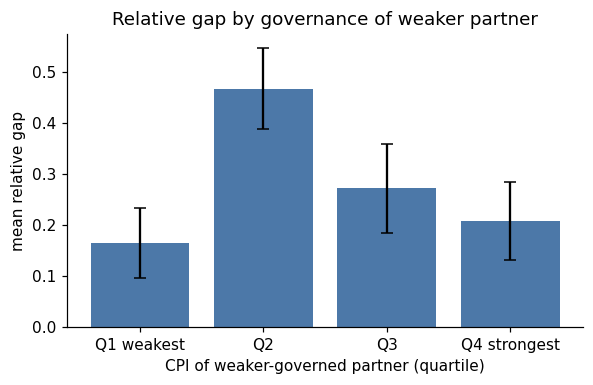

In [44]:
g_imp = gov.rename(columns={"code": "importer", "cpi": "cpi_imp"})
g_exp = gov.rename(columns={"code": "exporter", "cpi": "cpi_exp"})
pairs = series.merge(g_imp, on="importer").merge(g_exp, on="exporter")
print(f"Series with governance data on both sides: {len(pairs):,} of {len(series):,}")

pairs["cpi_min"] = pairs[["cpi_imp", "cpi_exp"]].min(axis=1)
pairs["cpi_mean"] = pairs[["cpi_imp", "cpi_exp"]].mean(axis=1)
pairs["cpi_absdiff"] = (pairs["cpi_imp"] - pairs["cpi_exp"]).abs()
pairs["weak_country"] = np.where(pairs["cpi_imp"] <= pairs["cpi_exp"], pairs["importer"], pairs["exporter"])
for c in ("cpi_imp", "cpi_exp", "cpi_min", "cpi_mean", "cpi_absdiff"):
    pairs[c + "_z"] = (pairs[c] - pairs[c].mean()) / pairs[c].std()
pairs = pairs.dropna(subset=["mean_rel_gap", "mean_sym_gap", "cpi_min"]).reset_index(drop=True)

def pool_rare(col, min_n=MIN_LEVEL):
    """Pool categories with fewer than min_n series into 'other' (keeps the regressions estimable on small samples)."""
    return col.where(col.map(col.value_counts()) >= min_n, "other")
pairs["class_c"], pairs["term_c"] = pool_rare(pairs["class_"]), pool_rare(pairs["term"])

print("Series by weaker-governed country (top 5):", pairs["weak_country"].value_counts().head(5).to_dict())
print(f"CPI of the weaker-governed partner in this sample: min {pairs['cpi_min'].min():.0f}, median {pairs['cpi_min'].median():.0f}, max {pairs['cpi_min'].max():.0f}")

# raw association
rho, p = st.spearmanr(pairs["cpi_min"], pairs["mean_rel_gap"])
R["rho"], R["rho_p"] = rho, p
print(f"Spearman correlation, cpi_min vs mean relative gap: rho = {rho:.3f}, p = {p:.3g}")

pairs["cpi_quartile"] = pd.qcut(pairs["cpi_min"].rank(method="first"), 4, labels=["Q1 weakest", "Q2", "Q3", "Q4 strongest"])
qt = pairs.groupby("cpi_quartile", observed=True)["mean_rel_gap"].agg(["mean", "sem", "size"])
display(qt)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(qt.index.astype(str), qt["mean"], yerr=1.96 * qt["sem"], color="#4c78a8", capsize=4)
ax.set(title="Relative gap by governance of weaker partner", ylabel="mean relative gap", xlabel="CPI of weaker-governed partner (quartile)")
plt.tight_layout(); plt.show()

In [45]:
# --- small regression toolkit (numpy/scipy only; no statsmodels needed) ---
def design(data, numeric, categorical=()):
    X = data[list(numeric)].astype(float).copy()
    if categorical:
        X = pd.concat([X, pd.get_dummies(data[list(categorical)], drop_first=True, dtype=float)], axis=1)
    X.insert(0, "const", 1.0)
    return X

def _cluster_meat(scores, groups):
    S = pd.DataFrame(scores).groupby(np.asarray(groups)).sum().to_numpy()
    return S.T @ S, S.shape[0]

def _table(beta, V, names, dof):
    se = np.sqrt(np.diag(V))
    tcrit = st.t.ppf(0.975, dof)
    p = 2 * st.t.sf(np.abs(beta / se), dof)
    return pd.DataFrame({"coef": beta, "se": se, "p": p,
                         "ci_low": beta - tcrit * se, "ci_high": beta + tcrit * se}, index=names)

def fit(y, data, numeric, categorical=(), logit=False, cluster="pair_id"):
    """OLS (or fractional logit if logit=True) with standard errors clustered by `cluster` (default: country pair)."""
    X = design(data, numeric, categorical)
    Xv, yv, groups = X.to_numpy(float), np.asarray(data[y], float), data[cluster].to_numpy()
    n, k = Xv.shape
    if not logit:
        bread = np.linalg.pinv(Xv.T @ Xv)
        beta = bread @ Xv.T @ yv
        u = yv - Xv @ beta
        meat, G = _cluster_meat(Xv * u[:, None], groups)
    else:  # IRLS for the Bernoulli quasi-likelihood (Papke-Wooldridge fractional logit)
        beta = np.zeros(k)
        for _ in range(100):
            eta = np.clip(Xv @ beta, -30, 30)
            mu = 1 / (1 + np.exp(-eta))
            w = np.clip(mu * (1 - mu), 1e-9, None)
            z = eta + (yv - mu) / w
            new = np.linalg.solve((Xv * w[:, None]).T @ Xv + 1e-9 * np.eye(k), (Xv * w[:, None]).T @ z)
            done = np.max(np.abs(new - beta)) < 1e-8
            beta = new
            if done:
                break
        mu = 1 / (1 + np.exp(-np.clip(Xv @ beta, -30, 30)))
        w = np.clip(mu * (1 - mu), 1e-9, None)
        bread = np.linalg.pinv((Xv * w[:, None]).T @ Xv)
        meat, G = _cluster_meat(Xv * (yv - mu)[:, None], groups)
    c = G / (G - 1) * (n - 1) / (n - k)          # small-sample correction (as in Stata / statsmodels)
    V = c * bread @ meat @ bread
    return _table(beta, V, list(X.columns), G - 1)

CTRL_NUM = ["log_vol"] + (["log_n"] if pairs["log_n"].nunique() > 1 else [])   # drop number-of-years control if all series cover one year
CTRL_CAT = ["class_c", "term_c"]

m1 = fit("mean_rel_gap", pairs, ["cpi_min_z"] + CTRL_NUM, CTRL_CAT)
m2 = fit("mean_rel_gap", pairs, ["cpi_exp_z", "cpi_imp_z"] + CTRL_NUM, CTRL_CAT)
m3 = fit("mean_rel_gap", pairs, ["cpi_min_z"] + CTRL_NUM, CTRL_CAT, logit=True)     # fractional logit (log-odds scale)
m4 = fit("mean_sym_gap", pairs, ["cpi_exp_z", "cpi_imp_z"] + CTRL_NUM, CTRL_CAT)    # direction

print("M1  OLS: relative gap ~ CPI of weaker partner");                  display(m1.loc[["cpi_min_z"]])
print("M2  OLS: relative gap ~ exporter CPI + importer CPI");             display(m2.loc[["cpi_exp_z", "cpi_imp_z"]])
print("M3  Fractional logit (coef on log-odds scale): same as M1");       display(m3.loc[["cpi_min_z"]])
print("M4  OLS: signed gap (E-I)/(E+I) ~ exporter CPI + importer CPI");   display(m4.loc[["cpi_exp_z", "cpi_imp_z"]])

m1b = fit("mean_rel_gap", pairs, ["cpi_min_z"] + CTRL_NUM, CTRL_CAT, cluster="weak_country")
print(f"M1b OLS: as M1, SEs clustered by the weaker-governed country ({pairs['weak_country'].nunique()} clusters; CPI is a country attribute)"); display(m1b.loc[["cpi_min_z"]])
R["m1b"], R["n_weak_clusters"] = m1b.loc["cpi_min_z"], pairs["weak_country"].nunique()

R["m1"] = m1.loc["cpi_min_z"]
R["m2"] = m2.loc[["cpi_exp_z", "cpi_imp_z"]]
R["m4"] = m4.loc[["cpi_exp_z", "cpi_imp_z"]]
R["gap_sd"] = pairs["mean_rel_gap"].std()

M1  OLS: relative gap ~ CPI of weaker partner


,coef,se,p,ci_low,ci_high
cpi_min_z,0.048,0.043,0.269,-0.038,0.133


M2  OLS: relative gap ~ exporter CPI + importer CPI


,coef,se,p,ci_low,ci_high
cpi_exp_z,0.042,0.053,0.434,-0.064,0.148
cpi_imp_z,0.014,0.055,0.796,-0.095,0.124


M3  Fractional logit (coef on log-odds scale): same as M1


,coef,se,p,ci_low,ci_high
cpi_min_z,0.244,0.222,0.276,-0.201,0.689


M4  OLS: signed gap (E-I)/(E+I) ~ exporter CPI + importer CPI


,coef,se,p,ci_low,ci_high
cpi_exp_z,0.045,0.030,0.137,-0.015,0.106
cpi_imp_z,0.044,0.039,0.273,-0.035,0.122


M1b OLS: as M1, SEs clustered by the weaker-governed country (16 clusters; CPI is a country attribute)


,coef,se,p,ci_low,ci_high
cpi_min_z,0.048,0.038,0.227,-0.033,0.128


### 4.4 Robustness
Three checks: restricting to better-measured series, dropping the smallest volumes (where rounding dominates), and a permutation test that reshuffles CPI across countries to see whether the association exceeds what arbitrary country labels produce.

In [46]:
top_weak = pairs["weak_country"].value_counts().index[0]      # most frequent weaker-governed country
specs = {
    "all series": pairs,
    "pairs with >= 3 series": pairs[pairs.groupby("pair_id")["pair_id"].transform("size") >= 3],
    "above-median volume": pairs[pairs["log_vol"] >= pairs["log_vol"].median()],
    "live animals only": pairs[pairs["term"] == "live"],
    f"excluding series involving {top_weak}": pairs[(pairs["importer"] != top_weak) & (pairs["exporter"] != top_weak)],
}
rows = []
for name, d in specs.items():
    if len(d) < 50 or d["pair_id"].nunique() < 10:
        continue
    c = fit("mean_rel_gap", d.reset_index(drop=True), ["cpi_min_z"] + CTRL_NUM, CTRL_CAT).loc["cpi_min_z"]
    rows.append({"sample": name, "n_series": len(d), "coef": c["coef"], "se": c["se"], "p": c["p"]})
rob = pd.DataFrame(rows); R["rob"] = rob
display(rob)

# permutation test at the country level (CPI is a country attribute)
codes = gov["code"].tolist(); cpi_vals = gov["cpi"].to_numpy()
idx = {c: i for i, c in enumerate(codes)}
ii = pairs["importer"].map(idx).to_numpy(); ee = pairs["exporter"].map(idx).to_numpy()
obs_rho = st.spearmanr(pairs["cpi_min"], pairs["mean_rel_gap"])[0]
perm = []
for _ in range(1000):
    shuffled = rng.permutation(cpi_vals)
    perm.append(st.spearmanr(np.minimum(shuffled[ii], shuffled[ee]), pairs["mean_rel_gap"])[0])
perm = np.array(perm)
R["perm_p"] = (np.sum(np.abs(perm) >= abs(obs_rho)) + 1) / (len(perm) + 1)
print(f"\nPermutation test: observed rho = {obs_rho:.3f}; null 95% range [{np.percentile(perm,2.5):.3f}, {np.percentile(perm,97.5):.3f}]; p = {R['perm_p']:.4f}")

,sample,n_series,coef,se,p
0,all series,220,0.048,0.043,0.269
1,pairs with >= 3 series,177,0.099,0.037,0.016
2,above-median volume,110,0.089,0.032,0.010
3,live animals only,54,0.059,0.077,0.460
4,excluding series involving TR,83,0.037,0.055,0.511



Permutation test: observed rho = 0.121; null 95% range [-0.360, 0.398]; p = 0.7692


## 5. Results and interpretation
The next cell prints the key numbers from the analysis above in one place. Read it together with the findings below.

In [47]:
print("DATA NOTE:", "SYNTHETIC - not real findings" if USE_SYNTHETIC else "real CITES + CPI data")
print(f"\nRQ1 - systematic?")
print(f"  exact matches: {R['share_exact']:.1%} | median relative gap {R['median_rel_gap']:.3f}, mean {R['mean_rel_gap']:.3f}")
print(f"  direction: exporter reports more in {R['pos']/(R['pos']+R['neg']):.1%} of non-zero gaps; pair-level mean symmetric gap {R['pair_mean_sym']:.3f} (Wilcoxon p = {R['wilcoxon_p']:.3g})")
print(f"  persistence: {R['persist_obs']:.3f} observed vs {R['persist_null']:.3f} null (p = {R['persist_p']:.4f}); ICC pair {R['icc_pair']:.3f}, series {R['icc_series']:.3f}")
print(f"\nRQ2 - governance")
print(f"  Spearman rho (cpi_min vs relative gap) = {R['rho']:.3f}; permutation p = {R['perm_p']:.4f}")
c = R["m1"]
print(f"  M1: +1 SD in cpi_min changes the relative gap by {c['coef']:.3f} (95% CI {c['ci_low']:.3f} to {c['ci_high']:.3f}); gap SD across series = {R['gap_sd']:.3f}")
print("  M2 / M4 coefficients (exporter vs importer CPI):")
display(pd.concat({"relative gap": R["m2"], "signed gap": R["m4"]}))

DATA NOTE: real CITES + CPI data

RQ1 - systematic?
  exact matches: 40.1% | median relative gap 0.170, mean 0.307
  direction: exporter reports more in 54.0% of non-zero gaps; pair-level mean symmetric gap 0.063 (Wilcoxon p = 0.0283)
  persistence: 0.502 observed vs 0.144 null (p = 0.0005); ICC pair 0.462, series nan

RQ2 - governance
  Spearman rho (cpi_min vs relative gap) = 0.121; permutation p = 0.7692
  M1: +1 SD in cpi_min changes the relative gap by 0.048 (95% CI -0.038 to 0.133); gap SD across series = 0.317
  M2 / M4 coefficients (exporter vs importer CPI):


coef    se     p  ci_low  ci_high
relative gap cpi_exp_z 0.042 0.053 0.434  -0.064    0.148
             cpi_imp_z 0.014 0.055 0.796  -0.095    0.124
signed gap   cpi_exp_z 0.045 0.030 0.137  -0.015    0.106
             cpi_imp_z 0.044 0.039 0.273  -0.035    0.122

### Findings (2025 reports, `reports.csv` and `CPI2025_Results.xlsx`)

**What the data can support.** Of 30,781 rows, 30,779 are from 2025 and 2 from 2026, so this is effectively a one-year analysis. After merging purpose, source and origin, 68.6% of year × species × term × pair cells hold only an exporter record, 29.5% only an importer record, and just **1.9% hold both**. The comparable sample is therefore **232 records across 55 country pairs and 119 taxa**, and every result below is tentative.

**RQ1: are the gaps systematic?** Partly yes.
- *Size (H1a, supported).* Only 40.1% of records match exactly. The mean relative gap is 0.31 and the median 0.17 (median across all records, including exact matches).
- *Direction (H1b, not supported overall).* Exporters report more in 54.0% of non-zero gaps (75 vs 64, binomial p = 0.40). The pair-level mean symmetric gap is +0.06 (Wilcoxon p = 0.03, t-test p = 0.11), which is weak and inconsistent. Direction differs by class: birds lean towards importer-higher figures (mean -0.22), but this comes mostly from one pair, Turkey importing from Czechia, where all 28 non-zero gaps have the importer reporting more. Reptiles, mammals and fish lean towards exporter-higher figures.
- *Persistence (H1c, supported but small-sample).* In the 11 pairs with at least three non-zero gaps, signs agree far more than chance (0.50 vs 0.14 expected, permutation p = 0.0005), and 46% of the variance of the symmetric gap lies between country pairs (ICC 0.46). Gaps look pair-specific rather than random noise. That fits differing recording conventions or one side under-recording, and these data cannot tell which. Only 11 pairs qualify, a few large ones (Turkey-Czechia, Turkey-Italy, Macao-France) carry much of the weight, and records in the same pair often share consignments.

**RQ2: are gaps larger with weaker governance?** No support in this sample.
- The correlation between the weaker partner's CPI and the relative gap is slightly *positive*, the opposite of H2a (Spearman rho = +0.12, p = 0.07; country-label permutation p = 0.77). In the regression, a 1 SD higher CPI of the weaker partner goes with a +0.048 change in the relative gap (95% CI -0.038 to +0.133, p = 0.27). Clustering by the weaker-governed country (16 clusters) gives p = 0.23. The interval rules out negative effects larger than about 0.04 per SD of CPI (roughly 0.12 SD of the gap), within this sample.
- Exporter and importer CPI separately are both small and insignificant, and neither predicts the direction of the gap (H2b not supported).
- Two robustness subsets show a *significant positive* coefficient (about +0.09 to +0.10, p of 0.010 and 0.016), but it disappears when series involving Turkey are excluded (+0.04, p = 0.51). The quartile means are not monotonic (0.17, 0.49, 0.25, 0.21). Treat the positive subset results as exploratory: several subsets were examined and none was specified in advance.

**Reading the null.** This is not evidence that governance does not matter. The sample is selected on timely filing by both sides, governance variation is concentrated in a few countries (mainly Turkey and Azerbaijan), and the CPI measures perceived corruption, not recording capacity. A fuller test needs a year with complete reports: set `YEAR_MIN`/`YEAR_MAX` and point `CITES_PATH` at an export for, say, 2022-2024, which would also allow persistence across years.

### Limitations to keep in view
- **Reported legal trade is not trafficking.** Gaps can signal unrecorded or misreported trade, but cannot by themselves distinguish fraud from error.
- **Benign sources of mismatch** remain: permit year vs shipment year, different term or unit conventions, taxonomic synonyms, re-export and origin handling, and rounding at small volumes. Aggregating by year and series reduces but does not remove these.
- **Non-reporting** is excluded from the gap measures; where governance is weak, missing reports may be the more important channel (see the reporting-status shares). Analysing it separately is a natural extension.
- **Reporting lag and selection.** The 2025 data are effectively one year (2 rows are from 2026), and only 38 importing and 50 exporting countries have filed anything yet, mostly EU members and Turkey. The gap can only be measured where *both* sides have filed, so the sample is selected on timely reporting, which may itself be related to administrative capacity.
- **Concentration.** Turkey is the weaker-governed partner in 132 of 220 series, so most of the governance variation comes from one country. Records within a country pair are not independent either, which is why the pair-level and country-level checks are reported.
- **Short window.** The CPI is a single 2025 score per country, so changes over time cannot be examined.
- **CPI** measures *perceived public-sector corruption* at the country level, not recording capacity. Governance is correlated with income, trade volume and administrative capacity, so the results are associations, not causal effects. Alternatives and additions worth trying: World Bank Worldwide Governance Indicators (control of corruption, government effectiveness, rule of law), and importer or exporter fixed effects in a specification that uses within-country variation over time.
- Many series are small, with few years; clustering by country pair accounts for dependence but not for every source of correlation (a two-way importer/exporter clustering would be a stronger check).

## 6. Conclusion

On the 2025 CITES reports available so far, exporter and importer figures disagree often and in a pair-specific way: 60% of comparable records do not match exactly, and gap signs agree within country pairs far more than chance, although there is no consistent overall direction. That supports reading the discrepancies as systematic rather than random noise. We find no evidence that the gaps are larger where the weaker trading partner has a lower CPI score; the estimate is slightly positive, imprecise, and not robust to dropping Turkey. Because only 1.9% of cells have reports from both sides, and filing so far is concentrated in a few countries, these results are best treated as a pilot. The notebook is set up to be rerun on a complete reporting year.

These are associations in reported legal trade. They do not measure illegal trade directly.

**Next steps:** Add World Bank governance indicators, model non-reporting separately, and use country fixed effects once several years are available.

## References and data sources

Links last checked November 2026. Cite the specific database version and download date you use.

1. CITES Trade Database, download page (full database, version 2026.1 at time of checking): <https://trade.cites.org/en/cites_trade/download>
2. CITES Trade Database Guide (explains the comparative tabulation and reported-quantity fields): <https://trade.cites.org/cites_trade_guidelines/en-CITES_Trade_Database_Guide.pdf>
3. Transparency International, Corruption Perceptions Index (official data and methodology): <https://www.transparency.org/en/cpi>
4. DataHub, Corruption Perceptions Index (covers 1995-2017 only, 0-10 scale, no country codes, so not used here): <https://datahub.io/core/corruption-perceptions-index>
5. Quality of Government Institute, Corruption Perceptions Index dataset: <https://datafinder.qog.gu.se/dataset/ti>
6. rOpenSci `citesdb` documentation, guidance on interpreting CITES shipment-level data: <https://rdrr.io/github/ropensci/citesdb/man/guidance.html>